# GNN V1CLD — Expériences

Notebook pour expérimenter avec l'architecture GNN qui prédit les multiplicateurs Lagrangiens λ
pour le bornage V1CLD du CC-MKP.

**Loss** : `L1(λ_GNN)` — borne supérieure Lagrangienne, à minimiser.  
**Référence** : subgradient T=200 avec pas 1/√(t+1), cold start λ=0.

## 1. Setup

In [ ]:
import sys, importlib
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Ajouter la racine du projet au path
REPO = Path("../").resolve()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# Import des fonctions du module d'entraînement
import gnn.train_gnn_v1cld as T
importlib.reload(T)   # recharge le module si modifié

from gnn.train_gnn_v1cld import (
    load_dataset, build_graph,
    GNN, lagrangian_v1cld, verify_v1cld,
    _solve_zeta_bb,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

## 2. Chargement des données

In [ ]:
DATA_DIR = REPO / "data" / "train_v1cld"
N_VAL    = 10   # taille des instances

graphs = load_dataset(
    DATA_DIR / f"instances_n{N_VAL}_gbab.txt",
    DATA_DIR / f"nodes_n{N_VAL}_gbab.txt",
)

print(f"\n{'idx':>4}  {'depth':>5}  {'n_g':>4}  {'N':>4}  {'m':>3}  "
      f"{'nodes':>7}  {'edges':>8}  {'opt':>8}")
print("-" * 60)
for i, g in enumerate(graphs):
    print(f"{i:4d}  {int(g.context[0].item()):5d}  {g.n_g:4d}  {g.N:4d}  {g.m:3d}  "
          f"{g.x.shape[0]:7d}  {g.edge_index.shape[1]:8d}  "
          f"{g.opt.item():8.2f}")

FileNotFoundError: [Errno 2] No such file or directory: '/Users/roman.lendormy/Documents/Cours/X25 - 3A/Stage/Learning_bounds_CCCP/data/train_v1cld/instances_n10_gbab.txt'

## 3. Références : L1(λ=0) et subgradient

In [ ]:
# Choisir le graphe sur lequel travailler
GRAPH_IDX = 0
g = graphs[GRAPH_IDX]

# L1 au départ (λ=0)
with torch.no_grad():
    lam0    = torch.zeros(g.N_z * g.m * g.n_g)
    l1_init = lagrangian_v1cld(lam0, g).item()

opt_val   = g.opt.item()
curr_cost = g.context[3].item()
depth     = int(g.context[0].item())

print(f"Graphe {GRAPH_IDX}  (depth={depth}, n_g={g.n_g}, N_z={g.N_z}, N={g.N}, m={g.m})")
print(f"  ε       = {g.epsilon.item():.2f}   n_fixed_1_z={g.n_fixed_1_z}")
print(f"  L1(λ=0) = {l1_init:.2f}   ← borne Lagrangienne de départ")
print(f"  opt     = {opt_val:.2f}   ← solution optimale")
print()

PRECISION = 1
PATIENCE  = 30
print(f"Subgradient convergence (precision={PRECISION}, patience={PATIENCE})...")
ref_subgrad = verify_v1cld(g, precision=PRECISION, patience=PATIENCE)
print(f"  converged : {ref_subgrad:.2f}  ({(l1_init - ref_subgrad)/l1_init*100:.1f}% vs L1(0))")

## 4. Configuration de l'entraînement

Modifier ici les hyperparamètres, puis ré-exécuter les cellules 5 et 6.

In [ ]:
CFG = dict(
    n_epochs  = 1000,
    lr        = 1e-3,
    # scheduler : "cosine", "step", "none"
    scheduler = "cosine",
    # pour scheduler="step" :
    step_size = 200,
    gamma     = 0.5,
    # pour scheduler="cosine" :
    eta_min   = 1e-5,
    # log tous les N epochs
    log_every = 50,
)

## 5. Entraînement

In [ ]:
torch.manual_seed(42)
device    = torch.device("cpu")
data      = g.to(device)

model     = GNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])

if CFG["scheduler"] == "cosine":
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CFG["n_epochs"], eta_min=CFG["eta_min"])
elif CFG["scheduler"] == "step":
    sched = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=CFG["step_size"], gamma=CFG["gamma"])
else:
    sched = None

history = []   # (epoch, L1, lr)

for epoch in range(1, CFG["n_epochs"] + 1):
    model.train()
    optimizer.zero_grad()
    lam  = model(data)
    loss = lagrangian_v1cld(lam, data)
    loss.backward()
    optimizer.step()
    if sched: sched.step()

    current_lr = optimizer.param_groups[0]["lr"]
    history.append((epoch, loss.item(), current_lr))

    if epoch % CFG["log_every"] == 0 or epoch == 1:
        b = loss.item()
        print(f"epoch {epoch:5d}  L1={b:9.2f}  "
              f"gap_opt={( b - opt_val)/opt_val*100:+6.1f}%  "
              f"gap_L1_0={(b - l1_init)/l1_init*100:+6.1f}%  "
              f"lr={current_lr:.2e}")

final_l1 = history[-1][1]
print(f"\nBorne finale : {final_l1:.2f}")
print(f"  vs L1(λ=0)        : {l1_init:.2f} ({(l1_init - final_l1)/l1_init*100:.1f}% amélioration)")
print(f"  vs subgradient ref: {ref_subgrad:.2f} ({'mieux' if final_l1 < ref_subgrad else 'moins bon'})")

epoch     1  L1=  4002.56  gap_opt= +91.9%  gap_L1_0=  +0.2%  lr=1.00e-03
epoch    50  L1=  3502.89  gap_opt= +68.0%  gap_L1_0= -12.3%  lr=9.94e-04
epoch   100  L1=  3454.53  gap_opt= +65.7%  gap_L1_0= -13.6%  lr=9.76e-04
epoch   150  L1=  3476.84  gap_opt= +66.7%  gap_L1_0= -13.0%  lr=9.46e-04
epoch   200  L1=  3438.28  gap_opt= +64.9%  gap_L1_0= -14.0%  lr=9.05e-04
epoch   250  L1=  3413.00  gap_opt= +63.7%  gap_L1_0= -14.6%  lr=8.55e-04
epoch   300  L1=  3400.91  gap_opt= +63.1%  gap_L1_0= -14.9%  lr=7.96e-04
epoch   350  L1=  3388.28  gap_opt= +62.5%  gap_L1_0= -15.2%  lr=7.30e-04
epoch   400  L1=  3363.22  gap_opt= +61.3%  gap_L1_0= -15.8%  lr=6.58e-04
epoch   450  L1=  3339.80  gap_opt= +60.2%  gap_L1_0= -16.4%  lr=5.82e-04
epoch   500  L1=  3308.01  gap_opt= +58.6%  gap_L1_0= -17.2%  lr=5.05e-04
epoch   550  L1=  3265.72  gap_opt= +56.6%  gap_L1_0= -18.3%  lr=4.28e-04
epoch   600  L1=  3241.86  gap_opt= +55.5%  gap_L1_0= -18.9%  lr=3.52e-04
epoch   650  L1=  3226.29  gap_opt= +5

In [ ]:
# ── Recharger pour avoir lam_init / return_n_iters ───────────────────────────
importlib.reload(T)
from gnn.train_gnn_v1cld import verify_v1cld

# ── λ_GNN comme warm start ────────────────────────────────────────────────────
model.eval()
with torch.no_grad():
    lam_gnn_np = model(data).numpy().reshape(g.N_z, g.m, g.n_g).astype(np.float64)

# 5 itérations subgradient depuis λ_GNN
l1_warm_5 = verify_v1cld(g, T=5, lam_init=lam_gnn_np)

# 60 itérations cold start
l1_cold_60 = verify_v1cld(g, T=60)

# Convergence complète cold start + nb itérations
l1_conv, n_iters_conv = verify_v1cld(
    g, T=500, precision=PRECISION, patience=PATIENCE, return_n_iters=True)

# ── Tableau récapitulatif ─────────────────────────────────────────────────────
rows = [
    ("L1(λ=0)  [départ]",                              l1_init),
    ("GNN seul",                                        final_l1),
    ("GNN + 5 it. subgrad  [warm start]",              l1_warm_5),
    ("Subgradient 60 it.  [cold start]",               l1_cold_60),
    (f"Subgradient convergé  [{n_iters_conv} it., prec={PRECISION}, pat={PATIENCE}]",
                                                        l1_conv),
    ("Optimum  [borne inf.]",                           opt_val),
]

W = max(len(r[0]) for r in rows)
print(f"{'':>{W}}   {'L1':>10}   {'vs opt':>9}   {'vs L1(0)':>10}")
print("─" * (W + 38))
for label, val in rows:
    gap_opt = (val - opt_val) / opt_val * 100
    gap_l0  = (val - l1_init) / l1_init * 100
    marker = "  ←" if "GNN" in label else ""
    print(f"{label:>{W}}   {val:10.2f}   {gap_opt:+8.1f}%   {gap_l0:+9.1f}%{marker}")

print()
gain_warm = final_l1 - l1_warm_5
print(f"Gain warm start (5 it.) vs GNN seul : {gain_warm:+.2f}  "
      f"({'mieux' if gain_warm > 0 else 'pas de gain'})")

                                                          L1      vs opt     vs L1(0)
─────────────────────────────────────────────────────────────────────────────────────
                              L1(λ=0)  [départ]      3996.01      +91.6%        +0.0%
                                       GNN seul      3189.31      +52.9%       -20.2%  ←
              GNN + 5 it. subgrad  [warm start]      3189.34      +52.9%       -20.2%  ←
               Subgradient 60 it.  [cold start]      3235.81      +55.2%       -19.0%
Subgradient convergé  [500 it., prec=1, pat=30]      3111.39      +49.2%       -22.1%
                          Optimum  [borne inf.]      2085.41       +0.0%       -47.8%

Gain warm start (5 it.) vs GNN seul : -0.03  (pas de gain)


## 6. Visualisation

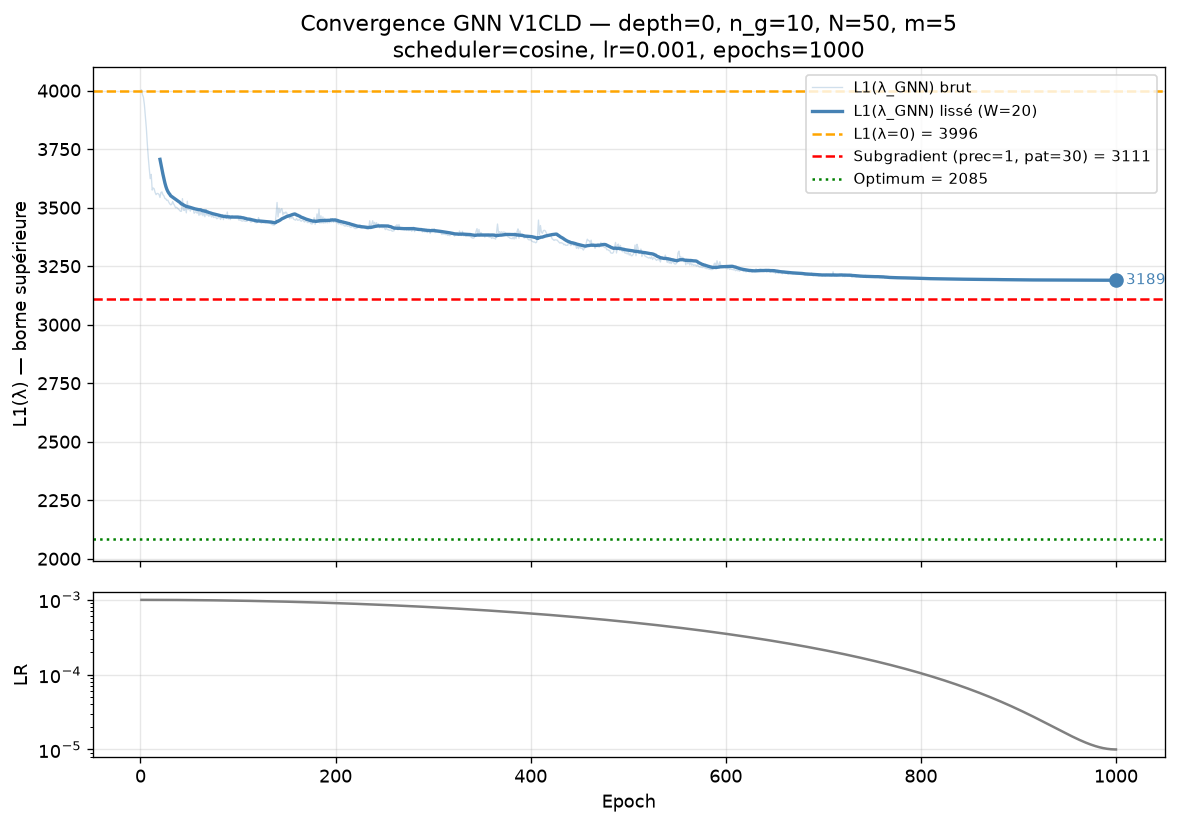

In [ ]:
epochs_h = [h[0] for h in history]
l1_h     = [h[1] for h in history]
lr_h     = [h[2] for h in history]

# Lissage (moving average)
W = 20
l1_smooth = np.convolve(l1_h, np.ones(W)/W, mode="valid")
ep_smooth = epochs_h[W-1:]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7),
                                gridspec_kw={"height_ratios": [3, 1]},
                                sharex=True)

# ── Courbe de convergence ──────────────────────────────────────────────────────
ax1.plot(epochs_h, l1_h, alpha=0.25, color="steelblue", lw=0.8, label="L1(λ_GNN) brut")
ax1.plot(ep_smooth, l1_smooth, color="steelblue", lw=2,
         label=f"L1(λ_GNN) lissé (W={W})")

# Lignes de référence
ax1.axhline(l1_init,    color="orange", lw=1.5, ls="--",
            label=f"L1(λ=0) = {l1_init:.0f}")
ax1.axhline(ref_subgrad, color="red",   lw=1.5, ls="--",
            label=f"Subgradient (prec={PRECISION}, pat={PATIENCE}) = {ref_subgrad:.0f}")
ax1.axhline(opt_val,    color="green",  lw=1.5, ls=":",
            label=f"Optimum = {opt_val:.0f}")

# Point final
ax1.scatter([epochs_h[-1]], [final_l1], color="steelblue", s=60, zorder=5)
ax1.annotate(f"  {final_l1:.0f}", (epochs_h[-1], final_l1),
             va="center", fontsize=9, color="steelblue")

ax1.set_ylabel("L1(λ) — borne supérieure")
ax1.set_title(
    f"Convergence GNN V1CLD — depth={depth}, n_g={g.n_g}, N={g.N}, m={g.m}\n"
    f"scheduler={CFG['scheduler']}, lr={CFG['lr']}, epochs={CFG['n_epochs']}"
)
ax1.legend(loc="upper right", fontsize=9)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))
ax1.grid(True, alpha=0.3)

# ── Learning rate ──────────────────────────────────────────────────────────────
ax2.semilogy(epochs_h, lr_h, color="gray", lw=1.5)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("LR")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(REPO / "gnn" / "convergence.png", bbox_inches="tight")
plt.show()

## 7. (Optionnel) Comparer plusieurs configs

Config : cosine lr=1e-3
  cosine lr=1e-3        final=3172.07
Config : cosine lr=3e-3
  cosine lr=3e-3        final=3369.47
Config : step lr=1e-3
  step lr=1e-3          final=3191.29
Config : aucun lr=1e-4
  aucun lr=1e-4         final=3312.34


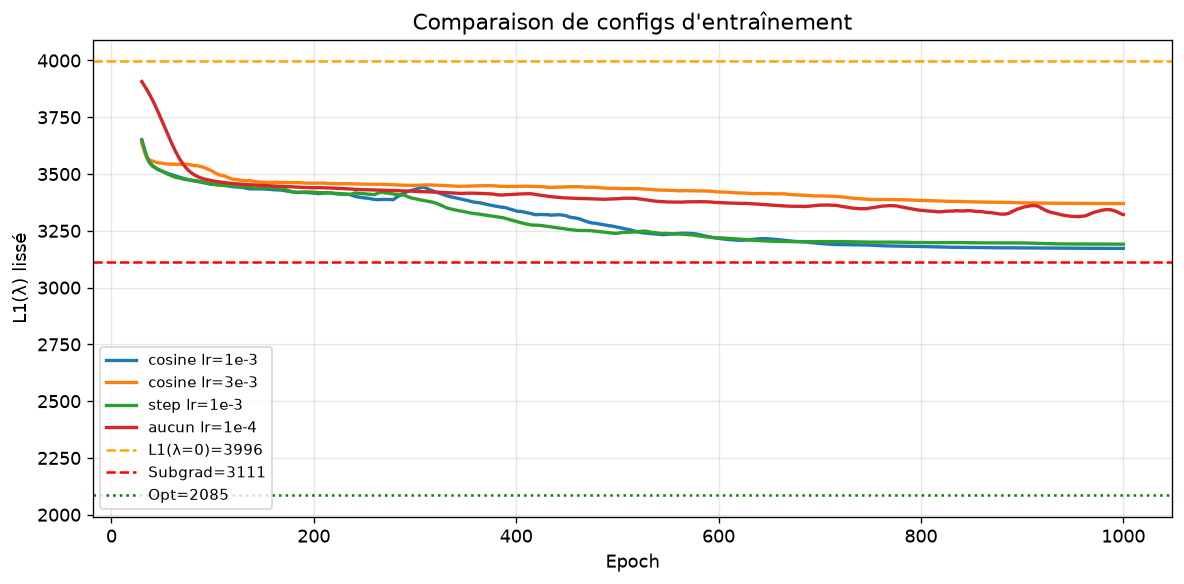

In [ ]:
def run_config(cfg, data, seed=42):
    """Entraîne le GNN avec une config donnée, retourne l'historique [(epoch, L1)]."""
    torch.manual_seed(seed)
    model     = GNN().to(data.x.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    n_epochs  = cfg["n_epochs"]

    if cfg["scheduler"] == "cosine":
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=n_epochs, eta_min=cfg.get("eta_min", 1e-5))
    elif cfg["scheduler"] == "step":
        sched = torch.optim.lr_scheduler.StepLR(
            optimizer, step_size=cfg["step_size"], gamma=cfg["gamma"])
    else:
        sched = None

    hist = []
    for epoch in range(1, n_epochs + 1):
        model.train(); optimizer.zero_grad()
        lam  = model(data)
        loss = lagrangian_v1cld(lam, data)
        loss.backward(); optimizer.step()
        if sched: sched.step()
        hist.append((epoch, loss.item()))

    print(f"  {cfg['label']:20s}  final={hist[-1][1]:.2f}")
    return hist


CONFIGS = [
    dict(label="cosine lr=1e-3",  n_epochs=1000, lr=1e-3, scheduler="cosine", eta_min=1e-5),
    dict(label="cosine lr=3e-3",  n_epochs=1000, lr=3e-3, scheduler="cosine", eta_min=1e-5),
    dict(label="step lr=1e-3",    n_epochs=1000, lr=1e-3, scheduler="step",   step_size=300, gamma=0.3),
    dict(label="aucun lr=1e-4",   n_epochs=1000, lr=1e-4, scheduler="none"),
]

results = {}
for cfg in CONFIGS:
    print(f"Config : {cfg['label']}")
    results[cfg["label"]] = run_config(cfg, data)

# ── Plot comparatif ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
colors  = plt.cm.tab10.colors

W = 30
for (label, hist), color in zip(results.items(), colors):
    ep   = [h[0] for h in hist]
    vals = [h[1] for h in hist]
    sm   = np.convolve(vals, np.ones(W)/W, mode="valid")
    ax.plot(ep[W-1:], sm, color=color, lw=2, label=label)

ax.axhline(l1_init,    color="orange", lw=1.5, ls="--", label=f"L1(λ=0)={l1_init:.0f}")
ax.axhline(ref_subgrad, color="red",   lw=1.5, ls="--", label=f"Subgrad={ref_subgrad:.0f}")
ax.axhline(opt_val,    color="green",  lw=1.5, ls=":",  label=f"Opt={opt_val:.0f}")

ax.set_xlabel("Epoch"); ax.set_ylabel("L1(λ) lissé")
ax.set_title("Comparaison de configs d'entraînement")
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(REPO / "gnn" / "convergence_compare.png", bbox_inches="tight")
plt.show()